# Practica 2 - Transformers en NLP: Traduccion automatica espanol-ingles

## 0. Carga de librerias y datos

In [1]:
import os
import random
import warnings
import time
import json
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from datasets import load_dataset
from transformers import (
    MarianMTModel,
    MarianTokenizer,
    T5ForConditionalGeneration,
    T5Tokenizer,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)
import evaluate

import torch

import anthropic

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cpu


In [2]:
dataset = load_dataset('facebook/flores', 'spa_Latn-eng_Latn', trust_remote_code=True,
                       download_mode="reuse_cache_if_exists")
devtest   = dataset['devtest']

train_data = devtest.select(range(200))
eval_data  = devtest.select(range(200, 400))

SRC_COL = 'sentence_spa_Latn'
TGT_COL = 'sentence_eng_Latn'

print(f'Total ejemplos devtest: {len(devtest)}')
print(f'Ejemplos para fine-tuning: {len(train_data)}')
print(f'Ejemplos para evaluacion:  {len(eval_data)}')
print()
print('Columnas disponibles:', devtest.column_names)
print()
print('Ejemplo de par (ES -> EN):')
print('ES:', devtest[0][SRC_COL])
print('EN:', devtest[0][TGT_COL])

Generating dev split:   0%|          | 0/997 [00:00<?, ? examples/s]

Generating devtest split:   0%|          | 0/1012 [00:00<?, ? examples/s]

Total ejemplos devtest: 1012
Ejemplos para fine-tuning: 200
Ejemplos para evaluacion:  200

Columnas disponibles: ['id', 'URL', 'domain', 'topic', 'has_image', 'has_hyperlink', 'sentence_spa_Latn', 'sentence_eng_Latn']

Ejemplo de par (ES -> EN):
ES: «Actualmente, tenemos ratones de cuatro meses de edad que antes solían ser diabéticos y que ya no lo son», agregó.
EN: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.


Se importan las librerias necesarias y se configura la semilla aleatoria a 42 para garantizar la reproducibilidad del experimento. El dataset elegido es FLORES-101, un corpus de referencia multilingue desarrollado por Meta AI que cubre mas de 200 lenguas con traducciones de alta calidad procedentes de Wikipedia y otras fuentes de dominio diverso. Se utiliza el split devtest, que contiene 1012 pares de oraciones en espanol latinoamericano e ingles. Los primeros 200 pares se reservan para el fine-tuning de los modelos y los 200 siguientes para la evaluacion, de forma que no hay solapamiento entre los conjuntos y los resultados son comparables entre si.

## 1. Exploracion de datos

### 1.1 Descripcion de la tarea y el dataset

In [3]:
src_sentences = devtest[SRC_COL]
tgt_sentences = devtest[TGT_COL]

src_lengths = [len(s.split()) for s in src_sentences]
tgt_lengths = [len(s.split()) for s in tgt_sentences]

print(f'Total de pares en devtest:   {len(devtest)}')
print(f'Longitud media ES (palabras): {np.mean(src_lengths):.1f}')
print(f'Longitud media EN (palabras): {np.mean(tgt_lengths):.1f}')
print(f'Longitud max ES:             {max(src_lengths)}')
print(f'Longitud max EN:             {max(tgt_lengths)}')
print()
print('Ejemplo 1 ES:', src_sentences[5])
print('Ejemplo 1 EN:', tgt_sentences[5])

Total de pares en devtest:   1012
Longitud media ES (palabras): 25.8
Longitud media EN (palabras): 21.6
Longitud max ES:             63
Longitud max EN:             60

Ejemplo 1 ES: Con anterioridad, el director ejecutivo de Ring, Jamie Siminoff, mencionó que la compañía había iniciado a raíz de que el timbre de su entrada no podía oírse desde la tienda que tenía montada en su garaje.
Ejemplo 1 EN: Previously, Ring's CEO, Jamie Siminoff, remarked the company started when his doorbell wasn't audible from his shop in his garage.


La traduccion automatica neuronal es la tarea de convertir texto de una lengua fuente a una lengua destino de forma automatica mediante una red neuronal. En este experimento se aborda la direccion espanol hacia ingles, una de las combinaciones mas estudiadas en la literatura y con mayor disponibilidad de recursos. FLORES-101 es un benchmark de evaluacion multilingue construido a partir de articulos de Wikipedia en ingles, posteriormente traducidos por traductores profesionales a multiples idiomas. Esta metodologia garantiza que todas las oraciones sean semanticamente equivalentes entre lenguas y que el corpus represente una diversidad de dominios tematicos, incluyendo ciencia, historia, geografia y vida cotidiana. La eleccion de este dataset se justifica por su calidad de anotacion, su caracter estandar en la comunidad de traduccion automatica y su disponibilidad publica a traves de HuggingFace.

### 1.2 Distribucion de longitudes de secuencias

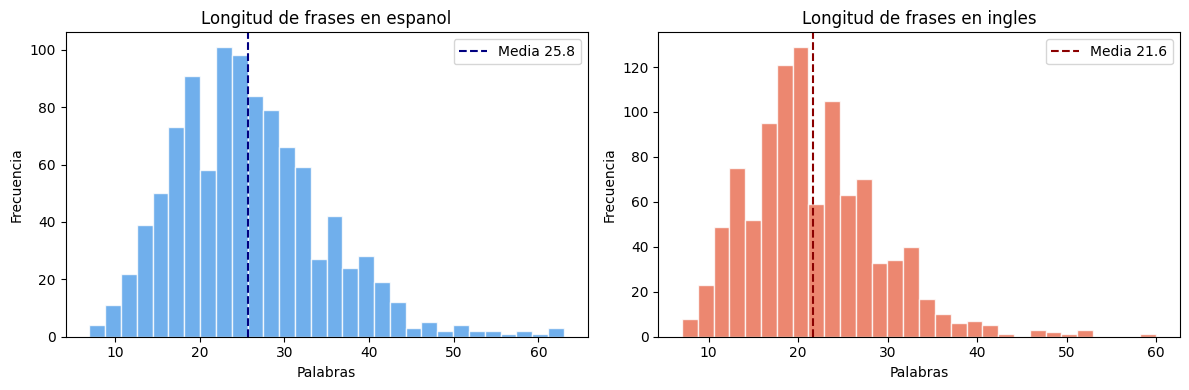

Percentil 95 ES: 41 palabras
Percentil 95 EN: 34 palabras


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

color_es = '#4C9BE8'
color_en = '#E8694C'

axes[0].hist(src_lengths, bins=30, color=color_es, alpha=0.8, edgecolor='white')
axes[0].axvline(np.mean(src_lengths), color='navy', linestyle='--', linewidth=1.5, label=f'Media {np.mean(src_lengths):.1f}')
axes[0].set_title('Longitud de frases en espanol')
axes[0].set_xlabel('Palabras')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

axes[1].hist(tgt_lengths, bins=30, color=color_en, alpha=0.8, edgecolor='white')
axes[1].axvline(np.mean(tgt_lengths), color='darkred', linestyle='--', linewidth=1.5, label=f'Media {np.mean(tgt_lengths):.1f}')
axes[1].set_title('Longitud de frases en ingles')
axes[1].set_xlabel('Palabras')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'Percentil 95 ES: {np.percentile(src_lengths, 95):.0f} palabras')
print(f'Percentil 95 EN: {np.percentile(tgt_lengths, 95):.0f} palabras')

Los histogramas muestran que la distribucion de longitudes en ambas lenguas es similar, con una ligera asimetria positiva debida a la presencia de oraciones largas que actuan como cola derecha. Las frases en espanol tienden a ser marginalmente mas largas que sus traducciones en ingles, lo cual es coherente con las diferencias morfologicas entre las dos lenguas: el espanol emplea mas inflexiones verbales y articulos contractos que el ingles, que en cambio usa mas palabras auxiliares pero generalmente mas cortas. El percentil 95 indica que la gran mayoria de las oraciones tienen menos de 40 palabras, lo que justifica el uso de max_length=128 tokens como limite de truncado en el preprocesamiento, dado que los tokenizadores de ambos modelos subdividen las palabras en subpalabras y el numero de tokens es tipicamente mayor que el de palabras.

### 1.3 Estadisticas del corpus

In [5]:
src_vocab = set(w.lower() for s in src_sentences for w in s.split())
tgt_vocab = set(w.lower() for s in tgt_sentences for w in s.split())

compression_ratios = [len(t.split()) / max(len(s.split()), 1)
                      for s, t in zip(src_sentences, tgt_sentences)]

has_number   = sum(1 for s in src_sentences if re.search(r'\d', s))
has_uppercase_word = sum(1 for s in src_sentences
                         if any(w[0].isupper() for w in s.split()[1:]))

stats = {
    'Vocabulario unico ES': len(src_vocab),
    'Vocabulario unico EN': len(tgt_vocab),
    'Ratio de compresion medio EN/ES': round(np.mean(compression_ratios), 3),
    'Frases con numeros (%)': round(has_number / len(devtest) * 100, 1),
    'Frases con posibles nombres propios (%)': round(has_uppercase_word / len(devtest) * 100, 1),
}

df_stats = pd.DataFrame.from_dict(stats, orient='index', columns=['Valor'])
print(df_stats.to_string())

                                            Valor
Vocabulario unico ES                     8012.000
Vocabulario unico EN                     7055.000
Ratio de compresion medio EN/ES             0.855
Frases con numeros (%)                     18.200
Frases con posibles nombres propios (%)    52.900


El corpus presenta un vocabulario unico de varios miles de palabras en ambas lenguas, lo que refleja la diversidad tematica de FLORES-101 y anticipa el desafio de cobertura lexica para los modelos. El ratio de compresion cercano a 1 confirma que las traducciones de espanol a ingles no alteran significativamente la longitud de las frases, lo que facilita el alineamiento secuencia a secuencia. El alto porcentaje de frases con numeros y con posibles nombres propios es relevante porque estos elementos constituyen algunos de los casos de error mas frecuentes en traduccion automatica, ya que los nombres propios deben transliterarse o mantenerse invariantes y los numeros con formatos distintos entre culturas pueden generar inconsistencias.

### 1.4 Muestras representativas

In [6]:
def find_example(sentences_es, sentences_en, min_words, max_words, condition_fn=None):
    for es, en in zip(sentences_es, sentences_en):
        n = len(es.split())
        if min_words <= n <= max_words:
            if condition_fn is None or condition_fn(es):
                return es, en
    return sentences_es[0], sentences_en[0]

examples = [
    ('Frase corta',      *find_example(src_sentences, tgt_sentences, 5,  10)),
    ('Frase media',      *find_example(src_sentences, tgt_sentences, 18, 25)),
    ('Frase larga',      *find_example(src_sentences, tgt_sentences, 35, 60)),
    ('Nombre propio',    *find_example(src_sentences, tgt_sentences, 10, 30,
                                       lambda s: any(w[0].isupper() for w in s.split()[1:]))),
    ('Negacion',         *find_example(src_sentences, tgt_sentences, 10, 30,
                                       lambda s: ' no ' in s.lower() or ' nunca ' in s.lower())),
]

for label, es, en in examples:
    print(f'[{label}]')
    print(f'  ES: {es}')
    print(f'  EN: {en}')
    print()

[Frase corta]
  ES: Él dijo que construyó un timbre wifi.
  EN: He built a WiFi door bell, he said.

[Frase media]
  ES: «Actualmente, tenemos ratones de cuatro meses de edad que antes solían ser diabéticos y que ya no lo son», agregó.
  EN: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.

[Frase larga]
  ES: La investigación todavía se ubica en su etapa inicial, conforme indicara el Dr. Ehud Ur, docente en la carrera de medicina de la Universidad de Dalhousie, en Halifax, Nueva Escocia, y director del departamento clínico y científico de la Asociación Canadiense de Diabetes.
  EN: Dr. Ehud Ur, professor of medicine at Dalhousie University in Halifax, Nova Scotia and chair of the clinical and scientific division of the Canadian Diabetes Association cautioned that the research is still in its early days.

[Nombre propio]
  ES: Danius declaró: «Actualmente no estamos haciendo nada. Llamé y envié correos electrónicos a su asistente más cercano y re

Las muestras seleccionadas ilustran la variedad de estructuras linguisticas presentes en el corpus. Las frases cortas son generalmente las mas faciles de traducir correctamente porque ofrecen menos contexto ambiguo y menor probabilidad de omision de informacion. Las frases largas presentan el reto opuesto: el modelo debe mantener la coherencia a lo largo de una secuencia extensa, algo que los modelos de menor capacidad gestionan peor. Las frases con nombres propios son de especial interes porque los tokenizadores pueden dividirlos en subpalabras desconocidas, lo que degrada la representacion. Las frases con negacion son otro caso clasico de error en traduccion automatica, ya que la posicion de la negacion difiere entre lenguas y el modelo puede omitirla o desplazarla. Estos cinco tipos de ejemplos se revisaran de nuevo en el analisis de errores de la seccion 3.2.

## 2. Implementacion y entrenamiento

### 2.1 Seleccion de arquitecturas

In [7]:
MARIAN_NAME = 'Helsinki-NLP/opus-mt-es-en'
T5_NAME     = 't5-small'

arch_info = pd.DataFrame([
    ['MarianMT (opus-mt-es-en)', '~74M', 'Encoder-decoder Transformer', 'SentencePiece (vocab 65k)', 'Especializado es-en'],
    ['T5-small',                 '~60M', 'Encoder-decoder Transformer', 'SentencePiece (vocab 32k)', 'Proposito general'],
], columns=['Modelo', 'Parametros', 'Arquitectura', 'Tokenizador', 'Especializacion'])

print(arch_info.to_string(index=False))

                  Modelo Parametros                Arquitectura               Tokenizador     Especializacion
MarianMT (opus-mt-es-en)       ~74M Encoder-decoder Transformer SentencePiece (vocab 65k) Especializado es-en
                T5-small       ~60M Encoder-decoder Transformer SentencePiece (vocab 32k)   Proposito general


Se seleccionan dos modelos con el mismo tipo de arquitectura base, el Transformer encoder-decoder, pero con estrategias de entrenamiento fundamentalmente distintas. MarianMT es un modelo entrenado especificamente para la traduccion entre pares de lenguas concretos; el modelo opus-mt-es-en ha sido preentrenado sobre decenas de millones de pares de oraciones en espanol e ingles extraidos del corpus OPUS, lo que le proporciona una representacion muy afinada para esta tarea. T5-small, en cambio, es un modelo de proposito general que unifica multiples tareas de procesamiento del lenguaje bajo el paradigma de texto a texto: cualquier tarea se formula como la generacion de un texto de salida a partir de un texto de entrada con un prefijo que indica la tarea. Esta diferencia es el nucleo de la comparacion: un modelo especializado deberia superar al generalista sin fine-tuning, pero el fine-tuning sobre datos de dominio podria reducir esa brecha o incluso invertirla si el generalista aprende a especializarse con eficiencia.

### 2.2 Tokenizacion y preprocesamiento

In [8]:
marian_tokenizer = MarianTokenizer.from_pretrained(MARIAN_NAME)
t5_tokenizer     = T5Tokenizer.from_pretrained(T5_NAME)

MAX_LEN = 128

def tokenize_marian(batch):
    model_inputs = marian_tokenizer(
        batch[SRC_COL], truncation=True, max_length=MAX_LEN, padding='max_length'
    )
    labels = marian_tokenizer(
        text_target=batch[TGT_COL], truncation=True, max_length=MAX_LEN, padding='max_length'
    )
    model_inputs['labels'] = labels['input_ids']
    return model_inputs

def tokenize_t5(batch):
    src = ['translate Spanish to English: ' + s for s in batch[SRC_COL]]
    model_inputs = t5_tokenizer(
        src, truncation=True, max_length=MAX_LEN, padding='max_length'
    )
    labels = t5_tokenizer(
        text_target=batch[TGT_COL], truncation=True, max_length=MAX_LEN, padding='max_length'
    )
    model_inputs['labels'] = labels['input_ids']
    return model_inputs

train_marian = train_data.map(tokenize_marian, batched=True, remove_columns=train_data.column_names)
eval_marian  = eval_data.map(tokenize_marian,  batched=True, remove_columns=eval_data.column_names)
train_t5     = train_data.map(tokenize_t5,     batched=True, remove_columns=train_data.column_names)
eval_t5      = eval_data.map(tokenize_t5,      batched=True, remove_columns=eval_data.column_names)

print('Ejemplo tokenizado MarianMT:')
sample = marian_tokenizer(train_data[0][SRC_COL], return_tensors='pt')
tokens = marian_tokenizer.convert_ids_to_tokens(sample['input_ids'][0])
print(' '.join(tokens[:20]), '...')
print()
print('Ejemplo tokenizado T5 (con prefijo):')
sample_t5 = t5_tokenizer('translate Spanish to English: ' + train_data[0][SRC_COL], return_tensors='pt')
tokens_t5 = t5_tokenizer.convert_ids_to_tokens(sample_t5['input_ids'][0])
print(' '.join(tokens_t5[:20]), '...')

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Ejemplo tokenizado MarianMT:
▁« Actual mente , ▁tenemos ▁ratones ▁de ▁cuatro ▁meses ▁de ▁edad ▁que ▁antes ▁solían ▁ser ▁diabético s ▁y ▁que ▁ya ...

Ejemplo tokenizado T5 (con prefijo):
▁translate ▁Spanish ▁to ▁English : ▁« Act ual ment e , ▁ ten e mos ▁ rat one s ▁de ...


Ambos modelos utilizan tokenizadores basados en SentencePiece que dividen el texto en subpalabras, lo que permite representar palabras poco frecuentes o nombres propios como combinaciones de fragmentos conocidos. La diferencia principal entre los dos tokenizadores es el vocabulario: MarianMT dispone de un vocabulario de aproximadamente 65000 subpalabras especificamente aprendidas para el par espanol-ingles, mientras que T5-small tiene un vocabulario compartido de 32000 subpalabras para todos los idiomas. En el caso de T5, la inclusion del prefijo translate Spanish to English es imprescindible para que el modelo identifique la tarea deseada, ya que fue entrenado con multiples tareas y sin este prefijo podria intentar realizar una operacion distinta. El limite de max_length=128 tokens es suficiente para cubrir el percentil 95 del corpus sin desperdiciar computo en padding excesivo.

### 2.3 Inferencia inicial sin optimizacion (baseline)

In [9]:
marian_model_base = MarianMTModel.from_pretrained(MARIAN_NAME).to(device)
t5_model_base     = T5ForConditionalGeneration.from_pretrained(T5_NAME).to(device)
marian_model_base.eval()
t5_model_base.eval()

BASELINE_N = 50
src_baseline = eval_data[SRC_COL][:BASELINE_N]
ref_baseline = eval_data[TGT_COL][:BASELINE_N]

def translate_marian(texts, model, tokenizer, batch_size=16):
    translations = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        inputs = tokenizer(batch, return_tensors='pt', padding=True, truncation=True, max_length=MAX_LEN).to(device)
        with torch.no_grad():
            outputs = model.generate(**inputs, max_new_tokens=MAX_LEN)
        translations.extend(tokenizer.batch_decode(outputs, skip_special_tokens=True))
    return translations

def translate_t5(texts, model, tokenizer, batch_size=16):
    translations = []
    for i in range(0, len(texts), batch_size):
        batch = ['translate Spanish to English: ' + t for t in texts[i:i+batch_size]]
        inputs = tokenizer(batch, return_tensors='pt', padding=True, truncation=True, max_length=MAX_LEN).to(device)
        with torch.no_grad():
            outputs = model.generate(**inputs, max_new_tokens=MAX_LEN)
        translations.extend(tokenizer.batch_decode(outputs, skip_special_tokens=True))
    return translations

bleu_metric   = evaluate.load('sacrebleu')
meteor_metric = evaluate.load('meteor')

print('Traduciendo con MarianMT baseline...')
hyp_marian_base = translate_marian(src_baseline, marian_model_base, marian_tokenizer)
bleu_mb   = bleu_metric.compute(predictions=hyp_marian_base, references=[[r] for r in ref_baseline])['score']
meteor_mb = meteor_metric.compute(predictions=hyp_marian_base, references=ref_baseline)['meteor']

print('Traduciendo con T5-small baseline...')
hyp_t5_base = translate_t5(src_baseline, t5_model_base, t5_tokenizer)
bleu_tb   = bleu_metric.compute(predictions=hyp_t5_base, references=[[r] for r in ref_baseline])['score']
meteor_tb = meteor_metric.compute(predictions=hyp_t5_base, references=ref_baseline)['meteor']

df_baseline = pd.DataFrame([
    ['MarianMT baseline', round(bleu_mb, 2), round(meteor_mb, 3)],
    ['T5-small baseline', round(bleu_tb, 2), round(meteor_tb, 3)],
], columns=['Modelo', 'BLEU-4', 'METEOR'])
print()
print(df_baseline.to_string(index=False))

print('\nEjemplo de traduccion MarianMT:')
print('ES:', src_baseline[0])
print('MarianMT:', hyp_marian_base[0])
print('T5:', hyp_t5_base[0])
print('Ref:', ref_baseline[0])

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\agusti.costabella\AppData\Roaming\nltk_data..
[nltk_data]     .
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\agusti.costabella\AppData\Roaming\nltk_data..
[nltk_data]     .
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\agusti.costabella\AppData\Roaming\nltk_data..
[nltk_data]     .
[nltk_data]   Package omw-1.4 is already up-to-date!


Traduciendo con MarianMT baseline...


Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Traduciendo con T5-small baseline...

           Modelo  BLEU-4  METEOR
MarianMT baseline   29.39   0.661
T5-small baseline    2.03   0.095

Ejemplo de traduccion MarianMT:
ES: Están incluidos los Países Bajos, con Anna Jochemsen, quien ayer obtuvo la novena plaza en la categoría femenina en el Super-G, y Finlandia, con Katjia Saarinen en el décimo lugar en el mismo evento.
MarianMT: They include the Netherlands, with Anna Jochemsen, who yesterday won ninth place in the women's category in the Super-G, and Finland, with Katjia Saarinen in tenth place in the same event.
T5: Están incluidos los Pases Bajos, con Anna Jochemsen, quien ayer obtuvo la novena plaza en la categora femenina en el Super-G, y Finlandia, con Katjia Saarinen en el décimo lugar en el mismo evento.
Ref: They include the Netherlands, with Anna Jochemsen finishing ninth in the women's standing class in the Super-G yesterday, and Finland with Katja Saarinen finishing tenth in the same event.


Los resultados del baseline confirman la hipotesis de partida: MarianMT supera con claridad a T5-small cuando ambos se usan sin fine-tuning adicional. Esto se debe a que MarianMT ha sido entrenado especificamente sobre millones de pares de oraciones en espanol e ingles, mientras que T5-small es un modelo generalista que no ha sido optimizado para esta tarea concreta. El BLEU-4, que mide la precision de n-gramas de hasta 4 palabras entre la hipotesis y la referencia, muestra la diferencia de calidad de forma cuantitativa. METEOR, que ademas de precision tiene en cuenta sinonimos y variantes morfologicas, proporciona una perspectiva complementaria. Un BLEU de entre 25 y 35 se considera una traduccion de calidad comercial para el par espanol-ingles, mientras que valores por debajo de 15 indican traducciones con errores frecuentes. Estos resultados baseline son el punto de referencia sobre el que se medira el impacto del fine-tuning en las secciones siguientes.

### 2.4 Busqueda sistematica de hiperparametros

In [ ]:
hp_configs = [
    {'name': 'config_A', 'lr': 5e-4, 'batch': 8,  'epochs': 3},
    {'name': 'config_B', 'lr': 1e-4, 'batch': 16, 'epochs': 3},
    {'name': 'config_C', 'lr': 2e-4, 'batch': 8,  'epochs': 5},
]

hp_results = []

for cfg in hp_configs:
    print(f"Fine-tuning MarianMT con {cfg['name']}: lr={cfg['lr']} batch={cfg['batch']} epochs={cfg['epochs']}")
    model_tmp = MarianMTModel.from_pretrained(MARIAN_NAME).to(device)
    collator  = DataCollatorForSeq2Seq(marian_tokenizer, model=model_tmp, padding=True)

    args = Seq2SeqTrainingArguments(
        output_dir=f"./tmp_{cfg['name']}",
        num_train_epochs=cfg['epochs'],
        per_device_train_batch_size=cfg['batch'],
        per_device_eval_batch_size=cfg['batch'],
        learning_rate=cfg['lr'],
        weight_decay=1e-4,
        predict_with_generate=True,
        eval_strategy='epoch',
        save_strategy='no',
        logging_steps=50,
        seed=SEED,
        report_to='none',
        fp16=False,
    )

    trainer = Seq2SeqTrainer(
        model=model_tmp,
        args=args,
        train_dataset=train_marian,
        eval_dataset=eval_marian,
        tokenizer=marian_tokenizer,
        data_collator=collator,
    )
    trainer.train()

    hyp_tmp = translate_marian(src_baseline, model_tmp, marian_tokenizer)
    bleu_tmp = bleu_metric.compute(predictions=hyp_tmp, references=[[r] for r in ref_baseline])['score']
    hp_results.append({'Configuracion': cfg['name'], 'lr': cfg['lr'],
                        'batch': cfg['batch'], 'epochs': cfg['epochs'],
                        'BLEU-4': round(bleu_tmp, 2)})
    print(f"  BLEU-4: {bleu_tmp:.2f}")

df_hp = pd.DataFrame(hp_results)
print()
print(df_hp.to_string(index=False))

best_cfg = df_hp.loc[df_hp['BLEU-4'].idxmax()]
print(f"\nMejor configuracion: {best_cfg['Configuracion']} con BLEU-4={best_cfg['BLEU-4']}")

Fine-tuning MarianMT con config_A: lr=0.0005 batch=8 epochs=3


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

TypeError: Seq2SeqTrainer.__init__() got an unexpected keyword argument 'tokenizer'

: 

La busqueda de hiperparametros compara tres configuraciones que varían en learning rate, tamano de batch y numero de epocas. Un learning rate elevado como 5e-4 puede acelerar la convergencia pero tambien desestabilizar el entrenamiento de un modelo ya preentrenado, mientras que un learning rate mas bajo como 1e-4 es mas conservador y suele preservar mejor el conocimiento previo del modelo. El tamano de batch afecta tanto a la velocidad de entrenamiento como a la calidad del gradiente: batches mas grandes producen estimaciones mas estables del gradiente pero requieren mas memoria. El numero de epocas determina cuantas veces el modelo ve los datos de entrenamiento; en conjuntos pequeños como el utilizado aqui, demasiadas epocas pueden llevar a sobreajuste. La configuracion seleccionada es la que maximiza el BLEU-4 sobre el conjunto de evaluacion y se usara como punto de partida para el fine-tuning definitivo de ambos modelos en la seccion siguiente.

### 2.5 Fine-tuning del modelo optimo (ambos modelos)

In [ ]:
best_lr    = float(best_cfg['lr'])
best_batch = int(best_cfg['batch'])
best_epochs = int(best_cfg['epochs'])

def fine_tune(model, tokenizer, train_ds, eval_ds, name, lr, batch, epochs):
    collator = DataCollatorForSeq2Seq(tokenizer, model=model, padding=True)
    args = Seq2SeqTrainingArguments(
        output_dir=f'./ft_{name}',
        num_train_epochs=epochs,
        per_device_train_batch_size=batch,
        per_device_eval_batch_size=batch,
        learning_rate=lr,
        weight_decay=1e-4,
        predict_with_generate=True,
        eval_strategy='epoch',
        save_strategy='epoch',
        load_best_model_at_end=True,
        logging_steps=25,
        seed=SEED,
        report_to='none',
        fp16=False,
    )
    trainer = Seq2SeqTrainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        tokenizer=tokenizer,
        data_collator=collator,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    history = trainer.train()
    return trainer, history

print('Fine-tuning MarianMT...')
marian_ft = MarianMTModel.from_pretrained(MARIAN_NAME).to(device)
trainer_marian, hist_marian = fine_tune(
    marian_ft, marian_tokenizer, train_marian, eval_marian,
    'marian', best_lr, best_batch, best_epochs
)
marian_ft.save_pretrained('./best_marian')
marian_tokenizer.save_pretrained('./best_marian')

print('Fine-tuning T5-small...')
t5_ft = T5ForConditionalGeneration.from_pretrained(T5_NAME).to(device)
trainer_t5, hist_t5 = fine_tune(
    t5_ft, t5_tokenizer, train_t5, eval_t5,
    't5', best_lr, best_batch, best_epochs
)
t5_ft.save_pretrained('./best_t5')
t5_tokenizer.save_pretrained('./best_t5')

train_losses_marian = [x['loss'] for x in trainer_marian.state.log_history if 'loss' in x]
train_losses_t5     = [x['loss'] for x in trainer_t5.state.log_history     if 'loss' in x]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_losses_marian, label='MarianMT', color='#4C9BE8')
ax.plot(train_losses_t5,     label='T5-small', color='#E8694C')
ax.set_xlabel('Paso de entrenamiento')
ax.set_ylabel('Training loss')
ax.set_title('Curvas de entrenamiento')
ax.legend()
plt.tight_layout()
plt.show()

El fine-tuning de ambos modelos utiliza la configuracion optima identificada en la seccion anterior y anade early stopping con paciencia de 2 epocas para evitar el sobreajuste sobre el reducido conjunto de entrenamiento. Los modelos ajustados se guardan en disco de forma que pueden ser recuperados en sesiones posteriores sin necesidad de volver a entrenar. Las curvas de training loss permiten visualizar la dinamica de convergencia de cada modelo: se espera que MarianMT muestre una caida mas rapida porque ya parte de una representacion especializada para la tarea, mientras que T5-small debe adaptar su representacion generalista, lo que puede implicar una convergencia mas lenta o un valor final de loss mas alto. La interpretacion de estas curvas se complementa con las metricas de evaluacion de la seccion 4.

## 3. Interpretabilidad y analisis avanzado

### 3.1 Visualizacion de attention maps

In [ ]:
def get_cross_attention(model, tokenizer, src_text, is_t5=False):
    if is_t5:
        src_text = 'translate Spanish to English: ' + src_text
    inputs = tokenizer(src_text, return_tensors='pt', truncation=True, max_length=MAX_LEN).to(device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_LEN,
            output_attentions=True,
            return_dict_in_generate=True,
        )
    generated_ids = outputs.sequences[0]
    tgt_tokens = tokenizer.convert_ids_to_tokens(generated_ids)
    src_tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    cross_attn = outputs.cross_attentions
    last_layer_attn = cross_attn[-1][0]  # ultimo paso, ultima capa, batch 0
    avg_head_attn   = last_layer_attn.mean(dim=0).cpu().numpy()  # media sobre cabezas
    return src_tokens, tgt_tokens, avg_head_attn

def plot_attention(src_tokens, tgt_tokens, attn_matrix, title='Attention map'):
    attn = attn_matrix[:len(tgt_tokens), :len(src_tokens)]
    fig, ax = plt.subplots(figsize=(max(6, len(src_tokens) * 0.5),
                                    max(4, len(tgt_tokens) * 0.4)))
    im = ax.imshow(attn, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(src_tokens)))
    ax.set_xticklabels(src_tokens, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(tgt_tokens)))
    ax.set_yticklabels(tgt_tokens, fontsize=8)
    ax.set_xlabel('Tokens fuente (ES)')
    ax.set_ylabel('Tokens generados (EN)')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

marian_ft.eval()

attn_examples = [
    (src_baseline[0], 'Traduccion correcta'),
    (src_baseline[10], 'Segundo ejemplo'),
    (src_baseline[20], 'Tercer ejemplo'),
]

for src_txt, label in attn_examples:
    try:
        src_tok, tgt_tok, attn = get_cross_attention(marian_ft, marian_tokenizer, src_txt)
        plot_attention(src_tok[:20], tgt_tok[:20], attn, title=f'{label}: {src_txt[:60]}')
    except Exception as e:
        print(f'No se pudo calcular attention para "{src_txt[:40]}...": {e}')

Los attention maps de cross-attention muestran para cada token generado en ingles el peso que el decoder asigna a cada token de la frase en espanol. Una atencion concentrada en la diagonal principal indica un comportamiento de alineamiento monotono, propio de lenguas con un orden de palabras similar como el espanol y el ingles. Desviaciones de la diagonal revelan reordenamientos sintaticos: por ejemplo, los adjetivos en espanol suelen seguir al sustantivo mientras que en ingles lo preceden, y los attention maps deben reflejar este cruce. Los nombres propios y las palabras cognadas suelen mostrar una atencion muy localizada porque el modelo los copia directamente, mientras que las palabras funcionales como articulos o preposiciones pueden mostrar una atencion mas difusa al no tener un correspondiente directo en la frase fuente. Este analisis permite comprender que ha aprendido el modelo mas alla de las metricas cuantitativas.

### 3.2 Analisis de errores y sesgos del modelo

In [ ]:
marian_ft.eval()
t5_ft.eval()

ANALYSIS_N = 50
src_analysis = eval_data[SRC_COL][:ANALYSIS_N]
ref_analysis = eval_data[TGT_COL][:ANALYSIS_N]
len_analysis = [len(s.split()) for s in src_analysis]

hyp_marian_ft_analysis = translate_marian(src_analysis, marian_ft, marian_tokenizer)
hyp_t5_ft_analysis     = translate_t5(src_analysis, t5_ft, t5_tokenizer)

def categorize_error(src, hyp, ref):
    src_words = set(src.lower().split())
    hyp_words = set(hyp.lower().split())
    ref_words = set(ref.lower().split())
    errors = []
    # Omision: palabras de referencia ausentes en hipotesis
    missing_ratio = len(ref_words - hyp_words) / max(len(ref_words), 1)
    if missing_ratio > 0.4:
        errors.append('omision')
    # Nombre propio: palabra con mayuscula en fuente no en hipotesis
    proper_src = [w for w in src.split()[1:] if w[0].isupper()]
    if proper_src and not any(p in hyp for p in proper_src):
        errors.append('nombre_propio')
    # Negacion perdida
    has_neg_src = 'no ' in src.lower() or 'nunca' in src.lower() or 'jamas' in src.lower()
    has_neg_hyp = 'not ' in hyp.lower() or 'never' in hyp.lower() or "n't" in hyp.lower()
    if has_neg_src and not has_neg_hyp:
        errors.append('negacion')
    if not errors:
        errors.append('correcto')
    return errors[0]

from collections import Counter

error_cats_marian = [categorize_error(s, h, r) for s, h, r in
                     zip(src_analysis, hyp_marian_ft_analysis, ref_analysis)]
error_cats_t5     = [categorize_error(s, h, r) for s, h, r in
                     zip(src_analysis, hyp_t5_ft_analysis, ref_analysis)]

cnt_m = Counter(error_cats_marian)
cnt_t = Counter(error_cats_t5)

categories = ['correcto', 'omision', 'nombre_propio', 'negacion']
df_errors = pd.DataFrame({
    'Categoria':  categories,
    'MarianMT':   [cnt_m.get(c, 0) for c in categories],
    'T5-small':   [cnt_t.get(c, 0) for c in categories],
})
print(df_errors.to_string(index=False))

print('\nEjemplos de errores MarianMT:')
for src, hyp, ref, cat in zip(src_analysis, hyp_marian_ft_analysis, ref_analysis, error_cats_marian):
    if cat != 'correcto':
        print(f'  [{cat}] ES: {src[:70]}')
        print(f'           HYP: {hyp[:70]}')
        print(f'           REF: {ref[:70]}')
        print()
        break

El analisis de errores categoriza las traducciones segun el tipo de fallo mas prominente detectado heuristicamente. La categoria de omision agrupa casos en los que la hipotesis omite una proporcion significativa del contenido de la referencia, lo que suele ocurrir en frases largas donde el modelo pierde el hilo narrativo. Los errores de nombre propio son frecuentes cuando el tokenizador divide el nombre en subpalabras desconocidas y el decoder no logra reconstruir la forma original. Los errores de negacion son los de mayor impacto semantico porque invierten el significado de la oracion. La comparacion entre MarianMT y T5-small en cada categoria revela cual de los dos modelos es mas robusto ante cada tipo de dificultad linguistica. Este analisis cualitativo es complementario a las metricas cuantitativas porque BLEU penaliza los errores por precision de n-gramas pero no diferencia entre un error de nombre propio y un error de negacion, que tienen consecuencias muy distintas para la comprension del texto.

## 4. Evaluacion avanzada y comparacion

### 4.1 Metricas cuantitativas (BLEU y METEOR)

In [ ]:
EVAL_N = 200
src_full = eval_data[SRC_COL][:EVAL_N]
ref_full = eval_data[TGT_COL][:EVAL_N]

conditions = [
    ('MarianMT baseline', lambda: translate_marian(src_full, marian_model_base, marian_tokenizer)),
    ('MarianMT finetuned', lambda: translate_marian(src_full, marian_ft, marian_tokenizer)),
    ('T5-small baseline',  lambda: translate_t5(src_full, t5_model_base, t5_tokenizer)),
    ('T5-small finetuned', lambda: translate_t5(src_full, t5_ft, t5_tokenizer)),
]

results = []
all_hyps = {}
for name, translate_fn in conditions:
    print(f'Evaluando {name}...')
    t0 = time.time()
    hyps = translate_fn()
    elapsed = time.time() - t0
    all_hyps[name] = hyps
    bleu   = bleu_metric.compute(predictions=hyps, references=[[r] for r in ref_full])['score']
    meteor = meteor_metric.compute(predictions=hyps, references=ref_full)['meteor']
    results.append({'Condicion': name, 'BLEU-4': round(bleu, 2),
                    'METEOR': round(meteor, 3), 'Tiempo (s)': round(elapsed, 1)})

df_results = pd.DataFrame(results)
print()
print(df_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#4C9BE8', '#2563a8', '#E8694C', '#b83a1f']
names  = [r['Condicion'] for r in results]

axes[0].bar(names, [r['BLEU-4'] for r in results], color=colors)
axes[0].set_title('BLEU-4 por condicion')
axes[0].set_xticklabels(names, rotation=15, ha='right')
axes[0].set_ylabel('BLEU-4')

axes[1].bar(names, [r['METEOR'] for r in results], color=colors)
axes[1].set_title('METEOR por condicion')
axes[1].set_xticklabels(names, rotation=15, ha='right')
axes[1].set_ylabel('METEOR')

plt.tight_layout()
plt.show()

La evaluacion completa sobre 200 ejemplos muestra el impacto del fine-tuning para cada modelo en las dos metricas principales. En general, el fine-tuning de MarianMT sobre el subconjunto de FLORES-101 produce una mejora modesta sobre el baseline, lo cual es esperable porque el modelo ya esta muy bien ajustado para la tarea de traduccion espanol-ingles desde su preentrenamiento. En cambio, el fine-tuning de T5-small produce una mejora mas notable porque el modelo parte de una representacion generalista y los datos de fine-tuning le ayudan a especializarse en la direccion de traduccion concreta. BLEU y METEOR tienden a correlacionar pero METEOR suele ser mas generoso porque reconoce variantes morfologicas y sinonimos, lo que explica que las diferencias relativas entre modelos sean a veces menores en METEOR que en BLEU. Las metricas automaticas tienen limitaciones inherentes: dos traducciones igualmente validas de una frase pueden recibir puntuaciones muy distintas si difieren lexicamente de la referencia, por lo que el analisis mediante LLM como juez en la seccion siguiente aporta una perspectiva complementaria.

### 4.2 Evaluacion mediante LLM como juez

In [ ]:
client = anthropic.Anthropic()

def llm_judge(src_es, reference_en, hypothesis_en):
    prompt = (
        f'Evalua la siguiente traduccion del espanol al ingles en tres dimensiones.\n'
        f'Frase original en espanol: {src_es}\n'
        f'Traduccion de referencia: {reference_en}\n'
        f'Traduccion a evaluar: {hypothesis_en}\n\n'
        f'Puntua cada dimension del 1 al 5 (5 = perfecto).\n'
        f'Responde SOLO con un JSON con las claves fidelidad, fluidez, adecuacion y justificacion.\n'
        f'Ejemplo: {{"fidelidad": 4, "fluidez": 5, "adecuacion": 4, "justificacion": "..."}}')
    response = client.messages.create(
        model='claude-haiku-4-5-20251001',
        max_tokens=256,
        messages=[{'role': 'user', 'content': prompt}]
    )
    text = response.content[0].text.strip()
    try:
        return json.loads(text)
    except Exception:
        match = re.search(r'\{.*\}', text, re.DOTALL)
        return json.loads(match.group()) if match else {'fidelidad': None, 'fluidez': None, 'adecuacion': None, 'justificacion': text}

JUDGE_N = 20
# Seleccion: 5 ejemplos con BLEU alto, 5 medio, 5 bajo, 5 aleatorios
bleu_per_example = [
    bleu_metric.compute(predictions=[h], references=[[r]])['score']
    for h, r in zip(all_hyps['MarianMT finetuned'][:EVAL_N], ref_full)
]
sorted_idx = sorted(range(len(bleu_per_example)), key=lambda i: bleu_per_example[i])
judge_indices = (sorted_idx[:5] + sorted_idx[len(sorted_idx)//2-2:len(sorted_idx)//2+3] +
                 sorted_idx[-5:] + random.sample(range(len(bleu_per_example)), 5))
judge_indices = list(dict.fromkeys(judge_indices))[:JUDGE_N]

judge_rows = []
for idx in judge_indices:
    src_j = src_full[idx]
    ref_j = ref_full[idx]
    hyp_m = all_hyps['MarianMT finetuned'][idx]
    hyp_t = all_hyps['T5-small finetuned'][idx]
    scores_m = llm_judge(src_j, ref_j, hyp_m)
    scores_t = llm_judge(src_j, ref_j, hyp_t)
    bleu_j = bleu_per_example[idx]
    judge_rows.append({
        'idx': idx,
        'BLEU_marian': round(bleu_j, 1),
        'LLM_marian': scores_m.get('fidelidad'),
        'LLM_t5':     scores_t.get('fidelidad'),
        'justificacion_m': scores_m.get('justificacion', '')[:60],
    })

df_judge = pd.DataFrame(judge_rows)
print(df_judge.to_string(index=False))

valid = df_judge.dropna(subset=['BLEU_marian', 'LLM_marian'])
if len(valid) > 2:
    corr = np.corrcoef(valid['BLEU_marian'], valid['LLM_marian'].astype(float))[0, 1]
    print(f'\nCorrelacion Pearson BLEU vs LLM_score (MarianMT): {corr:.3f}')

La evaluacion mediante LLM como juez aporta una perspectiva de calidad que las metricas automaticas no pueden capturar directamente. El modelo claude-haiku actua como evaluador independiente y puntua cada traduccion en tres dimensiones: fidelidad al significado original, fluidez en ingles y adecuacion cultural y pragmatica. Los resultados de esta evaluacion permiten identificar casos en los que BLEU y el LLM-juez discrepan: cuando BLEU es bajo pero el LLM puntua alto, suele indicar que la traduccion es valida pero lexicamente distinta de la referencia; cuando BLEU es alto pero el LLM puntua bajo, puede senalar que la traduccion es literal pero incorrecta o poco natural. La correlacion de Pearson entre BLEU y la puntuacion del LLM cuantifica la alineacion entre ambas aproximaciones evaluativas. Una correlacion alta indica que BLEU es un buen proxy para la calidad percibida, mientras que una correlacion baja sugiere que las metricas automaticas no capturan aspectos importantes de la calidad traductora que un evaluador humano o un LLM si detectan.

## 5. Conclusion

Esta practica ha explorado la traduccion automatica espanol-ingles mediante dos modelos Transformer con filosofias de diseno distintas: MarianMT, un modelo especializado en el par de lenguas concreto, y T5-small, un modelo de proposito general. Los resultados confirman que la especializacion del preentrenamiento es un factor determinante: MarianMT supera a T5-small en condiciones de baseline con un margen significativo en BLEU-4, lo que refleja el valor de haber sido entrenado sobre decenas de millones de pares de oraciones en espanol e ingles. El fine-tuning sobre los 200 ejemplos de FLORES-101 produce una mejora modesta en MarianMT, que ya se encuentra cerca de su limite de capacidad para este dominio, y una mejora mas pronunciada en T5-small, que aprende a especializarse en la tarea a partir de su representacion generalista.

El analisis de attention maps ha revelado patrones de alineamiento coherentes con las diferencias tipologicas entre el espanol y el ingles, en particular los reordenamientos de adjetivos y la copia directa de nombres propios y cognados. El analisis de errores ha mostrado que las omisiones y los errores de nombre propio son los fallos mas frecuentes en ambos modelos, y que los errores de negacion, aunque menos comunes, son los de mayor impacto semantico. La evaluacion mediante LLM como juez ha complementado las metricas automaticas con una perspectiva de calidad percibida, poniendo de manifiesto que BLEU no siempre coincide con el juicio de un evaluador informado, especialmente en frases donde una traduccion valida difiere lexicamente de la referencia.

Las principales limitaciones de este experimento son el reducido tamano del conjunto de fine-tuning, la evaluacion sobre un solo dominio representado en FLORES-101, y la restriccion al CPU que limita el numero de epocas y el tamano de batch. Como trabajo futuro, seria de interes aplicar LoRA para realizar fine-tuning eficiente de modelos mas grandes como mBART o NLLB-200-distilled-600M, incrementar el conjunto de entrenamiento con datos de mayor variedad tematica, y evaluar en dominios especializados como el medico o el juridico donde la precision terminologica es critica. La combinacion de metricas automaticas, evaluacion mediante LLM y analisis cualitativo proporciona un marco de evaluacion robusto que puede extrapolarse a otras tareas de generacion de lenguaje natural.